# Semana 6 · EDA + Feature Engineering + Baseline y variantes de los datos

**Tesis:** *Generalización de políticas de aprendizaje por refuerzo ante diferentes niveles de fidelidad de simulación*
**Alumno:** Brayan Bruce Pérez Escobar · **Rama:** `sprint3-eda-fe-datos`

## 0. Notas preliminares

### 0.1 Geometría del entorno

El entorno es una **bifurcación en Y en 2D**, en unidades adimensionales:

| Elemento | Valor | Nota |
|---|---|---|
| Ancho de los canales $W$ | 1 | Escala de longitud |
| Canal madre $L_0$ | 5 | Entrada a la izquierda |
| Ramas $L_1$ | 4 | A $\pm 30°$ del eje del canal madre |
| Rama objetivo | Superior | La otra rama es la salida "perdida" |
| Velocidad máxima del flujo $U_{\max}$ | 1 | En el centro del canal (R2–R4) |

- **Partículas:** se reparten al azar en una franja junto a la entrada.
- **Flujo:** sigue el eje de cada tramo con un **perfil de Poiseuille**: máximo en el centro y nulo en la pared. Por eso una partícula sin tamaño que se apoya en la pared queda inmóvil (defecto 2 del EDA).
- **Fin del recorrido:** una partícula queda entregada al cruzar el extremo de una rama.
- **Coordenadas:** las de la observación se miden desde el vértice de la bifurcación.

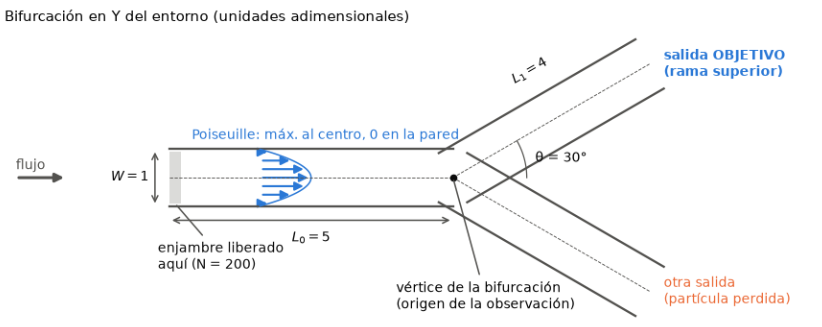

A considerar:
- Datos:  **observaciones** que el entorno entrega al agente en cada paso, un vector de features construido a partir del estado del enjambre. 
- El modelo (PPO), la recompensa, la física y el presupuesto de entrenamiento quedan fijos.

| Experimento | Datos que observa el agente | Pregunta |
|---|---|---|
| **Baseline** | 11 features | Referencia |
| **Var1 · margen** | 11 + margen de control $F_{\max}/(F_{\max}+U(t))$ | ¿Una feature derivada de dominio mejora el control en el flujo pulsátil? |
| **Var2 · sin fase** | 11 − fase del pulso $(\sin\varphi, \cos\varphi)$ | ¿El agente necesita saber en qué momento del latido está? |

Las tres se entrenan en **R3** (flujo pulsátil), donde el momento del latido importa, y se evalúan en R1–R4.

| Sección | Contenido |
|---|---|
| 1 | EDA de los datos |
| 2 | Feature engineering y pipeline |
| 3 | Experimento baseline (PPO) |
| 4 | Variantes 1 y 2 |
| 5 | Resultados comparables |
| 6 | Validación |
| 7 | Conclusiones |

In [17]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nanoswarm.agents.ppo_sb3 import TRAIN_SEED_BASE, PPOConfig, evaluate_runs
from nanoswarm.baselines import make_policy
from nanoswarm.envs.features import FEATURE_SETS, FeatureSet, feature_names
from nanoswarm.evaluation import ROOT, bootstrap_ci, episode_seeds, make_env
from nanoswarm.utils.rollout import run_metadata
from nanoswarm.variants import VARIANTS

T_START = time.time()
pd.set_option("display.precision", 3)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "figure.dpi": 110})
FS = ["base", "margen", "sin_fase"]
FS_LABEL = {"base": "Baseline (11 features)", "margen": "Var1 · + margen", "sin_fase": "Var2 · − fase"}
FS_COLOR = {"base": "#2a78d6", "margen": "#eb6834", "sin_fase": "#1baf7a"}
COND_COLOR = {"R1": "#2a78d6", "R2": "#eb6834", "R3": "#1baf7a", "R4": "#eda100"}
CONDS = ["R1", "R2", "R3", "R4"]
ENV = VARIANTS["var3"]
print(json.dumps(run_metadata(), indent=2, ensure_ascii=False))

{
  "fecha": "2026-10-23T19:10:36",
  "git_commit": "3bdad25 (con cambios sin commit)",
  "python": "3.12.7",
  "plataforma": "Windows-11-10.0.26200-SP0",
  "numpy": "2.5.3",
  "gymnasium": "1.4.0",
  "pandas": "3.0.6"
}


## 1. EDA de los datos

### 1.1 Construcción del dataset de observaciones

Se esta registrando cada paso de episodios en el entorno visto en la semana5 -  Sprint 2 (Var3), en los cuatro niveles, con dos políticas de comportamiento (aleatoria y heurística rama), para cubrir estados variados. Se usan **semillas de ajuste** (5000–5004); las de reporte quedan reservadas para evaluar. Se registran las 11 features base, la feature candidata *margen de control* y la recompensa del paso.

In [18]:
def collect(conditions=CONDS, policies=("random", "heur_branch"), seeds=episode_seeds("ajuste", 5)):
    rows = []
    for c in conditions:
        for p in policies:
            for s in seeds:
                env = FeatureSet(make_env(ENV, c), "margen")
                pol = make_policy(p, env.unwrapped, seed=s + 10_000)
                obs, _ = env.reset(seed=s)
                done, t = False, 0
                while not done:
                    nxt, r, term, trunc, info = env.step(pol(obs[:11]))
                    rows.append([c, p, s, t, *obs, r])
                    obs, t, done = nxt, t + 1, term or trunc
    return pd.DataFrame(rows, columns=["condition", "policy", "seed", "t", *feature_names("margen"), "reward"])


data = collect()
F = feature_names("margen")
print(f"{len(data):,} observaciones × {len(F)} features · nulos/infinitos: {int((~np.isfinite(data[F])).sum().sum())}")
data.groupby(["condition", "policy"]).size().unstack().rename_axis(index="nivel", columns="política")

17,503 observaciones × 12 features · nulos/infinitos: 0


política,heur_branch,random
nivel,,
R1,3170,4000
R2,1805,2292
R3,1744,2274
R4,958,1260


### 1.2 Distribución de las features por nivel de fidelidad

,R1 mean,R1 std,R2 mean,R2 std,R3 mean,R3 std,R4 mean,R4 std
centroid_x,-3.05,2.56,0.24,2.10,0.66,2.01,0.15,2.48
centroid_y,0.35,0.62,0.36,0.98,0.37,1.06,0.31,0.67
spread_x,0.04,0.02,0.87,0.49,0.82,0.48,0.76,0.35
spread_y,0.15,0.11,0.55,0.46,0.62,0.50,0.79,0.59
frac_target,0.00,0.05,0.21,0.22,0.33,0.24,0.21,0.25
frac_other,0.00,0.00,0.11,0.17,0.15,0.19,0.12,0.17
frac_active,1.00,0.05,0.67,0.33,0.52,0.33,0.67,0.37
phase_sin,0.08,0.70,0.05,0.71,0.05,0.71,0.52,0.47
phase_cos,-0.02,0.71,0.01,0.70,0.00,0.71,-0.06,0.71
prev_action_x,0.38,0.59,0.37,0.59,0.37,0.59,0.37,0.59


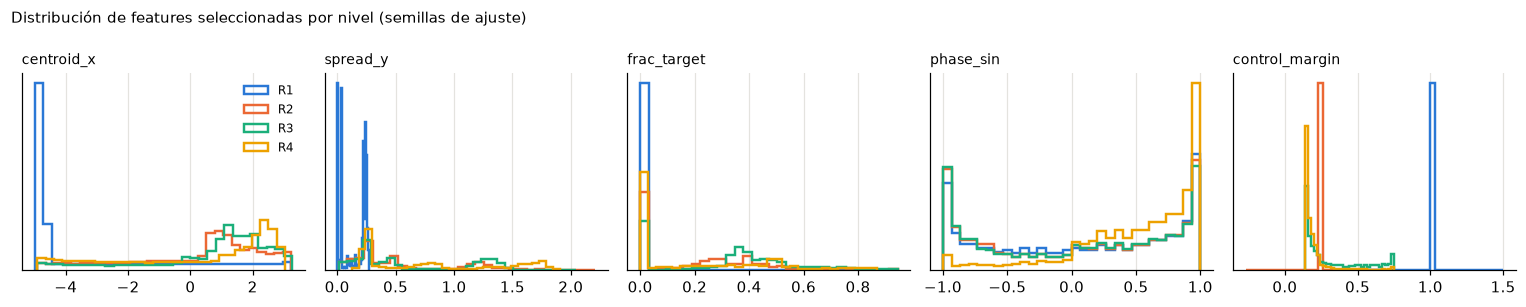

In [19]:
desc = data.groupby("condition")[F].agg(["mean", "std"]).T.unstack(level=1)
desc.columns = [f"{c} {s}" for c, s in desc.columns]
display(desc.round(2))

show = ["centroid_x", "spread_y", "frac_target", "phase_sin", "control_margin"]
fig, axes = plt.subplots(1, len(show), figsize=(14, 2.8))
for ax, f in zip(axes, show):
    for c in CONDS:
        ax.hist(data.loc[data.condition == c, f], bins=30, histtype="step", lw=1.6, density=True, color=COND_COLOR[c], label=c)
    ax.set_title(f, fontsize=9, loc="left"); ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Distribución de features seleccionadas por nivel (semillas de ajuste)", x=0.01, ha="left", fontsize=10)
fig.tight_layout(); plt.show()

### 1.3 Redundancia entre features (correlación y VIF)

El VIF (*variance inflation factor*) mide cuánto se explica una feature con las demás: valores > 10 indican colinealidad fuerte.

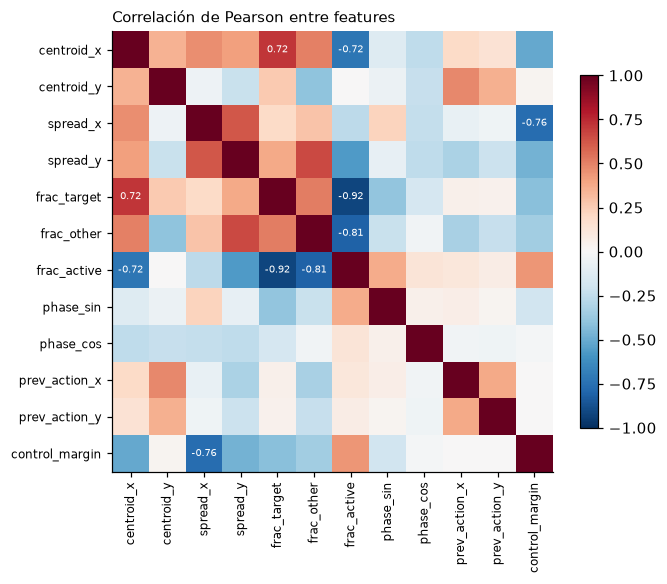

frac_target + frac_other + frac_active: min 1.000000, max 1.000000


,VIF
centroid_x,4.6
centroid_y,2.9
spread_x,4.8
spread_y,3.3
frac_target,∞ (colineal)
frac_other,∞ (colineal)
frac_active,∞ (colineal)
phase_sin,1.5
phase_cos,1.4
prev_action_x,1.6


In [20]:
C = np.corrcoef(data[F].to_numpy().T)
def vif_of(X):
    # VIF_j = 1 / (1 − R²_j), con R²_j de regresar la feature j sobre las demás
    out = []
    for j in range(X.shape[1]):
        y, Z = X[:, j], np.c_[np.ones(len(X)), np.delete(X, j, axis=1)]
        resid = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
        r2 = 1 - resid.var() / y.var()
        out.append(np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2))
    return np.array(out)


vif = pd.Series(vif_of(data[F].to_numpy()), index=F, name="VIF")
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(F)), F, rotation=90, fontsize=8); ax.set_yticks(range(len(F)), F, fontsize=8); ax.grid(False)
for i in range(len(F)):
    for j in range(len(F)):
        if abs(C[i, j]) >= 0.7 and i != j:
            ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white")
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Correlación de Pearson entre features", loc="left", fontsize=10)
plt.show()
suma = data[["frac_target", "frac_other", "frac_active"]].sum(axis=1)
print(f"frac_target + frac_other + frac_active: min {suma.min():.6f}, max {suma.max():.6f}")
vif.map(lambda v: f"{v:.1f}" if np.isfinite(v) else "∞ (colineal)").to_frame()

### 1.4 La feature candidata: margen de control frente a la fase

El margen $m_t = F_{\max}/(F_{\max}+U(t))$ dice cuánto domina la fuerza de control sobre el flujo en ese instante: 1 sin flujo; cerca de 0 con flujo rápido.

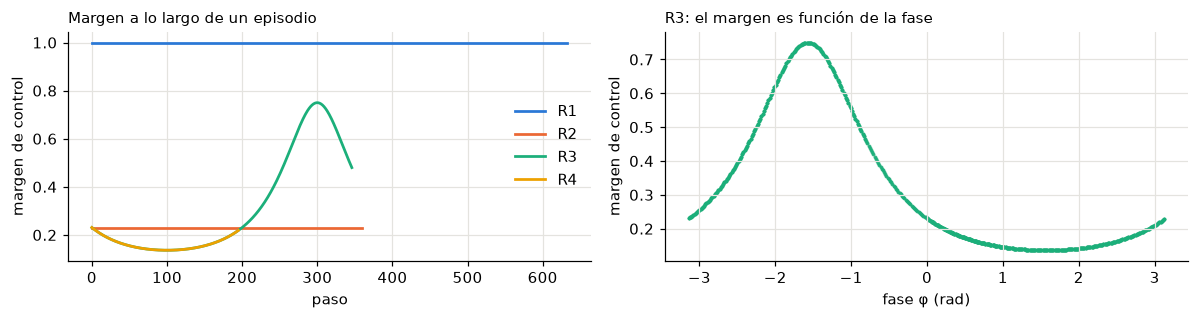

            mean    std    min    max
condition                            
R1         1.000  0.000  1.000  1.000
R2         0.231  0.000  0.231  0.231
R3         0.310  0.201  0.136  0.750
R4         0.191  0.098  0.136  0.750


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
ep = data[(data.policy == "heur_branch") & (data.seed == data.seed.min())]
for c in CONDS:
    e = ep[ep.condition == c]
    axes[0].plot(e.t, e.control_margin, color=COND_COLOR[c], lw=1.8, label=c)
axes[0].set_xlabel("paso"); axes[0].set_ylabel("margen de control")
axes[0].legend(frameon=False, loc="center right", bbox_to_anchor=(1.0, 0.5))
axes[0].set_title("Margen a lo largo de un episodio", loc="left", fontsize=10)
r3 = data[data.condition == "R3"]
axes[1].scatter(np.arctan2(r3.phase_sin, r3.phase_cos), r3.control_margin, s=2, color=COND_COLOR["R3"], alpha=0.3)
axes[1].set_xlabel("fase φ (rad)"); axes[1].set_ylabel("margen de control")
axes[1].set_title("R3: el margen es función de la fase", loc="left", fontsize=10)
fig.tight_layout(); plt.show()
print(data.groupby("condition").control_margin.agg(["mean", "std", "min", "max"]).round(3))

### 1.5 Hallazgos del EDA y decisiones

Media de la fase por nivel (debería ser ≈ 0 si se recorre el ciclo completo):

In [22]:
fase = data.groupby("condition")[["phase_sin", "phase_cos"]].mean().round(2)
print(fase.to_string())

           phase_sin  phase_cos
condition                      
R1              0.08      -0.02
R2              0.05       0.01
R3              0.05       0.00
R4              0.52      -0.06


| # | Hallazgo | Decisión |
|:---:|---|---|
| 1 | **Datos limpios:** sin nulos ni infinitos | Sin imputación |
| 2 | **Escalas distintas:** el centroide x llega a ±5; las fracciones y la fase están en [0, 1] o [−1, 1] | Estandarizar (sección 2.3), ajustando solo con entrenamiento |
| 3 | **Colinealidad perfecta:** entregada + perdida + activa = 1 (VIF → ∞) | Redundancia inocua para PPO; candidata a eliminar en un experimento posterior |
| 4 | **El margen solo varía en R3 (y R4):** constante en R1 (1.0) y R2 (≈ 0.23) | **Var1:** agregarlo, porque condensa en una variable lo que la fase solo da de forma indirecta. Riesgo registrado: en R1–R2 identifica el nivel |
| 5 | **En R3 el margen es una función de la fase:** la fase ya contiene la información, pero en forma no lineal | **Var2:** quitar la fase, para medir si el agente realmente usa el momento del latido |
| 6 | **Fase sesgada en R4:** la media del seno es ≈ 0.5, porque los episodios empiezan en la misma fase y R4 termina antes | Limitación conocida (Sprint 2). Cambio candidato: fase inicial aleatoria |

## 2. Feature engineering y pipeline

### 2.1 Features base (11)

| Feature | A partir de | Técnica |
|---|---|---|
| Centroide $(x, y)$, relativo al vértice | 200 posiciones | Creación (estadístico de grupo) + cambio de origen |
| Dispersión $(x, y)$ | 200 posiciones | Creación (desviación estándar) |
| Fracciones entregada, perdida y activa | Estado de cada partícula | Ratios (conteo / $N$) |
| Fase $(\sin\varphi, \cos\varphi)$ | Tiempo $t$ | Codificación cíclica |
| Acción previa $a_{t-1}$ | Acción del paso anterior | Lag |

### 2.2 Feature nueva (Var1): margen de control

$$m_t = \frac{F_{\max}}{F_{\max} + U(t)} \in (0, 1]$$

- **Qué es:** feature derivada de dominio, análoga al "margen de seguridad" de la clase (capacidad / esfuerzo).
- **Por qué no la razón directa $F_{\max}/U(t)$:** no está definida en R1 ($U = 0$); la forma acotada sí lo está.
- **Implementación:** el envoltorio `FeatureSet` (en `src/nanoswarm/envs/features.py`) agrega o quita columnas de la observación sin tocar la física ni la recompensa.

In [23]:
pd.DataFrame({fs: {"n features": len(feature_names(fs)), "quita": ", ".join(FEATURE_SETS[fs]["drop"]) or "—",
                   "agrega": ", ".join(FEATURE_SETS[fs]["add"]) or "—"} for fs in FS}).T.rename(index=FS_LABEL)

,n features,quita,agrega
Baseline (11 features),11,—,—
Var1 · + margen,12,—,control_margin
Var2 · − fase,9,"phase_sin, phase_cos",—


### 2.3 Transformación y partición (cero fuga)

**Estandarización** $(x-\mu)/\sigma$ con `VecNormalize` de Stable-Baselines3:
- **Durante el entrenamiento:** μ y σ se actualizan **solo** con las observaciones de entrenamiento.
- **Al evaluar:** se guardan en `obs_rms.npz` y se aplican **congeladas**.
- **En la evaluación cruzada:** una política entrenada en R3 que se evalúa en R1 usa las μ y σ de R3, no las de R1.

**Partición por semillas** (en RL los datos los genera el simulador; lo que se particiona son las semillas):

| Partición | Semillas de episodio | Uso |
|---|---|---|
| Entrenamiento | $100\,000 + $ (por corrida) | Interacción de PPO y ajuste de μ y σ |
| Ajuste | 5000–5019 | EDA (sección 1) y validación (sección 6) |
| Reporte | 9000–9029 | Solo resultados finales |

In [24]:
cfg = PPOConfig()
train_seeds = {(TRAIN_SEED_BASE + s) * 100 + r for s in range(3) for r in range(cfg.n_envs)}
assert not train_seeds & set(episode_seeds("ajuste")) and not train_seeds & set(episode_seeds("reporte"))
assert not set(episode_seeds("ajuste")) & set(episode_seeds("reporte"))
print(f"Semillas iniciales de entrenamiento: {sorted(train_seeds)[:3]}… · disjuntas de ajuste y reporte ✓")

Semillas iniciales de entrenamiento: [100000, 100001, 100002]… · disjuntas de ajuste y reporte ✓


## 3. Experimento baseline: PPO con las 11 features

**Configuración fija para todos los experimentos:**

| Elemento | Valor |
|---|---|
| Algoritmo | PPO (Stable-Baselines3), MLP 64 × 64 |
| Tasa de aprendizaje α | $3\cdot10^{-4}$, constante (por defecto de SB3; la elección con rejilla queda para el piloto completo) |
| Presupuesto | 300 000 pasos por corrida |
| Entornos en paralelo | 4 (2048 transiciones por actualización) |
| γ | 0.995 |
| Nivel de entrenamiento | R3 |
| Semillas de entrenamiento | 3 por experimento |

El entrenamiento tarda ~15 min para las 9 corridas en paralelo, así que el notebook **carga** las corridas guardadas en `experiments/pilot/`. Con `RETRAIN = True` las vuelve a entrenar desde cero.

In [25]:
RETRAIN = False
SEEDS = [0, 1, 2]
RUNS = {fs: [ROOT / "experiments" / "pilot" / f"{fs}_R3_s{s}" for s in SEEDS] for fs in FS}
if RETRAIN:
    import subprocess, sys
    subprocess.run([sys.executable, str(ROOT / "scripts" / "train.py"), "--feature-sets", *FS,
                    "--condition", "R3", "--seeds", *map(str, SEEDS)], check=True)
meta = pd.DataFrame([json.loads((r / "meta.json").read_text(encoding="utf-8")) for rs in RUNS.values() for r in rs])
print(meta[["feature_set", "condition", "seed", "train_seconds"]].to_string(index=False))

feature_set condition  seed  train_seconds
       base        R3     0       1151.714
       base        R3     1       1144.837
       base        R3     2       1149.670
     margen        R3     0       1152.883
     margen        R3     1       1160.288
     margen        R3     2       1151.324
   sin_fase        R3     0       1152.707
   sin_fase        R3     1       1147.543
   sin_fase        R3     2        954.350


In [26]:
t0 = time.time()
ev = evaluate_runs([r for rs in RUNS.values() for r in rs], CONDS, episode_seeds("reporte"))
EVAL_SECONDS = time.time() - t0
heur = pd.read_csv(ROOT / "results" / "tables" / "episodes_sprint2_var3.csv")  # mismo entorno y semillas de reporte
heur = heur[heur.policy.isin(["zero", "heur_branch"])]
ev.to_csv(ROOT / "results" / "tables" / "episodes_sprint3_ppo.csv", index=False)
print(f"Evaluación: {len(ev)} episodios en {EVAL_SECONDS:.0f} s")

base = ev[ev.feature_set == "base"]
ref = pd.concat([
    heur.groupby(["policy", "condition"]).eta.mean().unstack().rename(index={"zero": "Sin fuerza", "heur_branch": "Heur. rama"}),
    base.groupby("condition").eta.mean().to_frame("PPO baseline").T])
ref.style.format("{:.3f}").set_caption("η en semillas de reporte · PPO entrenado en R3 (media de 3 semillas)")

Evaluación: 1080 episodios en 262 s


condition,R1,R2,R3,R4
Heur. rama,0.980,0.955,0.954,0.871
Sin fuerza,0.000,0.469,0.469,0.472
PPO baseline,0.335,0.892,0.968,0.888


## 4. Variantes de los datos

Mismo algoritmo, configuración, nivel de entrenamiento y semillas que el baseline; **solo cambia la observación** (sección 2.2):
- **Var1 · margen:** 12 features.
- **Var2 · sin fase:** 9 features.

In [27]:
per_seed = ev.groupby(["feature_set", "train_seed", "condition"]).eta.mean().unstack()
per_seed.rename(index=FS_LABEL, level=0).style.format("{:.3f}").set_caption("η por semilla de entrenamiento y nivel de evaluación")

## 5. Resultados comparables

### 5.1 Tabla estándar

**Columnas:**
- **η R3 (principal):** desempeño en el nivel de entrenamiento.
- **η R1, R2, R4:** desempeño en los otros niveles; **brecha** = η(R3) − η(otro).
- **Secundarias:** pérdida en la otra rama, tiempo de tránsito, esfuerzo de control, **eficiencia muestral** (área bajo la curva de aprendizaje, η medio durante el entrenamiento) y **estabilidad** (desviación estándar de η R3 entre las 3 semillas).
- **Costo:** minutos de entrenamiento por corrida.

Todo se mide con semillas de reporte; el valor es la media de las 3 semillas de entrenamiento.

In [28]:
def curve(run):
    return pd.read_csv(run / "curve.csv")


rows = []
for fs in FS:
    e = ev[ev.feature_set == fs]
    r3 = e[e.condition == "R3"]
    seed_eta = r3.groupby("train_seed").eta.mean()
    auc = np.mean([curve(r).eta.mean() for r in RUNS[fs]])
    rows.append({"experimento": FS_LABEL[fs], "n features": len(feature_names(fs)),
                 **{f"η {c}": e[e.condition == c].eta.mean() for c in CONDS},
                 "brecha R3→R2": r3.eta.mean() - e[e.condition == "R2"].eta.mean(),
                 "brecha R3→R4": r3.eta.mean() - e[e.condition == "R4"].eta.mean(),
                 "pérdida R3": r3.eta_other.mean(), "tránsito R3": r3.transit.mean(), "esfuerzo R3": r3.effort.mean(),
                 "efic. muestral": auc, "desv. entre semillas": seed_eta.std(),
                 "costo (min)": meta[meta.feature_set == fs].train_seconds.mean() / 60})
table = pd.DataFrame(rows).set_index("experimento")
(ROOT / "logs").mkdir(exist_ok=True)
with open(ROOT / "logs" / "metrics_sprint3_variantes_datos.txt", "w", encoding="utf-8") as f:
    f.write("# Sprint 3: variantes de los datos (PPO entrenado en R3, semillas de reporte 9000–9029)\n\n")
    f.write("## Metadatos\n" + json.dumps(run_metadata(), indent=2, ensure_ascii=False) + "\n\n")
    f.write("## Configuración PPO\n" + json.dumps(meta.iloc[0]["config"], indent=2) + "\n\n")
    f.write("## Tabla estándar\n" + table.to_string(float_format=lambda x: f"{x:.3f}") + "\n\n")
    f.write("## η por semilla de entrenamiento\n" + per_seed.to_string(float_format=lambda x: f"{x:.3f}") + "\n")
table.style.format(precision=3).format("{:.1f}", subset=["costo (min)"]).format("{:d}", subset=["n features"])

,n features,η R1,η R2,η R3,η R4,brecha R3→R2,brecha R3→R4,pérdida R3,tránsito R3,esfuerzo R3,efic. muestral,desv. entre semillas,costo (min)
experimento,,,,,,,,,,,,,
Baseline (11 features),11,0.335,0.892,0.968,0.888,0.075,0.079,0.000,6.318,0.988,0.926,0.010,19.1
Var1 · + margen,12,0.000,0.957,0.966,0.893,0.008,0.073,0.000,6.328,0.974,0.932,0.005,19.2
Var2 · − fase,9,0.972,0.960,0.965,0.868,0.004,0.097,0.000,6.591,1.000,0.924,0.011,18.1


### 5.2 Gráfico clave: curvas de aprendizaje y desempeño por nivel

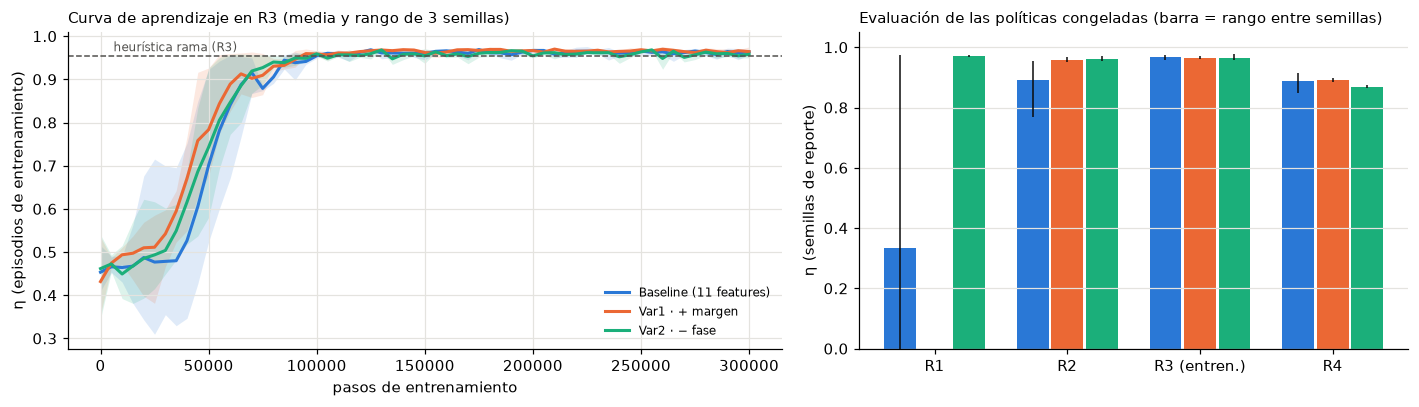

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
grid = np.linspace(0, cfg.timesteps, 61)
for fs in FS:
    ys = []
    for run in RUNS[fs]:
        c = curve(run)
        smooth = c.eta.rolling(30, min_periods=1).mean()
        ys.append(np.interp(grid, c.timestep, smooth))
    ys = np.array(ys)
    axes[0].plot(grid, ys.mean(0), color=FS_COLOR[fs], lw=2, label=FS_LABEL[fs])
    axes[0].fill_between(grid, ys.min(0), ys.max(0), color=FS_COLOR[fs], alpha=0.15, lw=0)
axes[0].axhline(heur[(heur.policy == "heur_branch") & (heur.condition == "R3")].eta.mean(), color="#52514e", ls="--", lw=1)
axes[0].text(cfg.timesteps * 0.02, 0.965, "heurística rama (R3)", fontsize=8, color="#52514e")
axes[0].set_xlabel("pasos de entrenamiento"); axes[0].set_ylabel("η (episodios de entrenamiento)")
axes[0].set_title("Curva de aprendizaje en R3 (media y rango de 3 semillas)", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")

x = np.arange(len(CONDS)); w = 0.26
for k, fs in enumerate(FS):
    s = ev[ev.feature_set == fs].groupby(["condition", "train_seed"]).eta.mean()
    m = [s[c].mean() for c in CONDS]
    lo = [s[c].min() for c in CONDS]; hi = [s[c].max() for c in CONDS]
    axes[1].bar(x + (k - 1) * w, m, w * 0.92, color=FS_COLOR[fs], label=FS_LABEL[fs])
    axes[1].errorbar(x + (k - 1) * w, m, yerr=[np.subtract(m, lo), np.subtract(hi, m)], fmt="none", ecolor="#0b0b0b", lw=1)
axes[1].set_xticks(x, [f"{c}{' (entren.)' if c == 'R3' else ''}" for c in CONDS]); axes[1].set_ylim(0, 1.05)
axes[1].grid(axis="x", visible=False); axes[1].set_ylabel("η (semillas de reporte)")
axes[1].set_title("Evaluación de las políticas congeladas (barra = rango entre semillas)", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "fig6_sprint3_variantes_datos.png", bbox_inches="tight", dpi=130)
plt.show()

### 5.3 Diagnóstico: por qué difiere la transferencia a R1

En R1 no hay flujo: solo la fuerza de control mueve el enjambre, y debe empujarlo hacia la salida durante casi todo el horizonte (la heurística rama tarda ~630 de 800 pasos). Se registra, en un episodio de reporte en R1, la acción media de cada política y el valor estandarizado (*z*, con μ y σ de R3) de las features que cambian de nivel.

In [30]:
from nanoswarm.agents.ppo_sb3 import FrozenPolicy

rows = []
for fs in FS:
    for s, run in zip(SEEDS, RUNS[fs]):
        pol = FrozenPolicy(run)
        env = FeatureSet(make_env(ENV, "R1"), fs)
        obs, _ = env.reset(seed=episode_seeds("reporte")[0])
        acts, zs = [], []
        for _ in range(300):
            a = np.clip(pol(obs), -1, 1); a = a / max(1, np.linalg.norm(a))
            acts.append(a); zs.append((obs - pol.mean) / pol.std)
            obs, *_ = env.step(a)
        acts, zs, names = np.array(acts), np.array(zs), feature_names(fs)
        rows.append({"experimento": FS_LABEL[fs], "semilla": s,
                     "η R1": ev[(ev.feature_set == fs) & (ev.train_seed == s) & (ev.condition == "R1")].eta.mean(),
                     "empuje hacia la salida (F_x medio)": acts[:, 0].mean(),
                     "empuje lateral (F_y medio)": acts[:, 1].mean(),
                     "z máx. de la fase": np.abs(zs[:, [names.index(n) for n in names if n.startswith("phase")]]).max() if fs != "sin_fase" else np.nan,
                     "z del margen": np.abs(zs[:, names.index("control_margin")]).max() if fs == "margen" else np.nan})
pd.DataFrame(rows).set_index(["experimento", "semilla"]).style.format(precision=2, na_rep="—")

**Lectura.**
- **Var1 · margen:** en R1 el margen vale 1.0, fuera del rango visto en R3 (0.14–0.75): estandarizado con la μ y σ de R3 queda a 7–9 desviaciones, un dato **fuera de distribución**. En dos semillas la política responde empujando **hacia atrás** (F_x < 0); en la tercera empuja hacia adelante en promedio, pero tampoco entrega. Es el riesgo anotado en el EDA (hallazgo 4): una feature que **identifica el nivel** ata la política al nivel en que se entrenó.
- **Baseline:** el empuje medio de los primeros 300 pasos es parecido en las tres semillas (la semilla 2 incluso empuja más hacia la salida que la 0), y sin embargo solo la semilla 0 entrega. **La causa no se explica con la acción media**: queda pendiente un análisis paso a paso, por ejemplo del comportamiento junto a la bifurcación y de su dependencia de la fase.
- **Var2 · sin fase:** las tres semillas empujan hacia adelante de forma sostenida y transfieren a R1.


## 6. Validación

Dos comprobaciones de que los resultados no dependen de los datos con que se obtuvieron:
1. **Entre semillas de entrenamiento:** 3 corridas independientes por experimento (tabla 5.1, columna "desv. entre semillas", y barras del gráfico).
2. **Holdout de episodios:** cada política congelada se evalúa en R3 también con las semillas de ajuste. Si η coincide con el de reporte, el resultado no depende de los episodios de evaluación.

In [31]:
ev_a = evaluate_runs([r for rs in RUNS.values() for r in rs], ["R3"], episode_seeds("ajuste"))
hold = pd.DataFrame({"ajuste": ev_a.groupby(["feature_set", "train_seed"]).eta.mean(),
                     "reporte": ev[ev.condition == "R3"].groupby(["feature_set", "train_seed"]).eta.mean()})
hold["Δ"] = hold["reporte"] - hold["ajuste"]
last = {(fs, s): curve(r).eta.tail(30).mean() for fs in FS for s, r in zip(SEEDS, RUNS[fs])}
hold["entrenamiento (últimos 30 ep.)"] = [last[k] for k in hold.index]
print(f"máx |Δη| ajuste–reporte: {hold['Δ'].abs().max():.3f}")
hold.rename(index=FS_LABEL, level=0).style.format("{:.3f}")

máx |Δη| ajuste–reporte: 0.007


## 7. Conclusiones

### 7.1 Resultados (semillas de reporte, media de 3 semillas de entrenamiento)

| Experimento | η R3 (entren.) | η R1 | η R2 | η R4 | ¿Mejora frente al baseline? |
|---|---|---|---|---|---|
| Baseline · 11 features | 0.968 | 0.335 (0.97 / 0.03 / 0.00) | 0.892 | 0.888 | — |
| Var1 · + margen | 0.966 | **0.000** | 0.957 | 0.893 | No en el nivel de entrenamiento; **falla en R1** |
| Var2 · − fase | 0.965 | **0.972** | **0.960** | 0.868 | No en el nivel de entrenamiento; **mejor transferencia a R1–R2** |

**Referencias en R3:** heurística rama 0.954 y sin fuerza 0.469. PPO aprende la tarea en las 9 corridas y supera a la mejor regla fija en R3 (0.97 frente a 0.95) y en R4 (0.89 frente a 0.87).

### 7.2 Qué aportó cada variante de los datos

1. **En el nivel de entrenamiento (R3) los tres conjuntos de features rinden igual** (0.965–0.968, diferencias dentro del ruido entre semillas). Agregar el margen o quitar la fase no cambia lo que PPO logra donde se entrenó: la información de la fase no es necesaria para resolver R3 con este presupuesto.
2. **Fuera del nivel de entrenamiento, los datos sí cambian el resultado.** Es la pregunta de la tesis apareciendo en el diseño de la observación:
   - **El margen (Var1) empeora la generalización:** en R1 toma un valor que nunca vio (fuera de distribución) y la política falla por completo.
   - **Quitar la fase (Var2) la mejora:** transfiere a R1 y R2 en las 3 semillas. A cambio, pierde 0.02 en R4.
   - **El baseline es inestable:** su transferencia a R1 depende de la semilla.
3. **Lección de feature engineering para la tesis:** una feature que es buena "en casa" puede ser una fuente de sobreajuste al simulador. Las features que **identifican el nivel de fidelidad** (el margen) o que permiten aprender estrategias **dependientes de la física del nivel** (la fase) aumentan la brecha de fidelidad.

### 7.3 Validación

- **Episodios:** η en R3 coincide entre semillas de ajuste y de reporte (|Δη| ≤ 0.007), y también con el η de los últimos episodios de entrenamiento.
- **Semillas de entrenamiento:** la desviación entre semillas en R3 es ≤ 0.011.
- **Fuera de R3 la variabilidad entre semillas es grande** (baseline en R1: 0.97 / 0.03 / 0.00). Con 3 semillas, las conclusiones fuera del nivel de entrenamiento son **indicios**, no resultados confirmatorios.

### 7.4 Limitaciones

- 3 semillas y un solo nivel de entrenamiento (R3).
- **R1 deja poco margen de tiempo** (800 pasos frente a ~630 que necesita una política ideal), y el mecanismo del fallo del baseline en R1 no está diagnosticado (sección 5.3).
- Fase inicial fija y colinealidad de las fracciones, sin tratar.
- α fijo en $3\cdot10^{-4}$, sin rejilla.

### 7.5 Decisión y siguiente experimento

- **Se adopta Var2 (sin fase) como observación candidata** para la matriz $\pi_{R_i}(R_j)$: rinde igual en casa y generaliza mejor. **Se descarta el margen** en su forma actual.
- **Siguiente experimento (un cambio):** entrenar con la observación sin fase en los cuatro niveles (R1–R4) y llenar la primera matriz de evaluación cruzada 4 × 4, con más semillas.
- **Riesgos a controlar:**
  - Repetir la comparación base frente a sin fase en la matriz completa, para confirmar que no es un efecto de R3.
  - Fase inicial aleatoria.
  - Revisar el horizonte de R1.